# Lab 08: Vision Transformers and VLMs, Talking to Your Images

**ITAI 1378  |  Module 08 Companion Lab  |  2026**

**Author:** Patricia McManus     **Collaborator:** Claude (Anthropic)

**Course:** AI and Robotics Program, Digital and Information Technology Center of Excellence, Houston City College

---

In Module 08 you learned how Vision Transformers chop an image into patches and treat them like words, and how Vision Language Models (VLMs) connect a model's eyes to a language model so it can describe, answer, and reason about images. The frontier VLMs you studied (GPT-5.5, Claude Opus 4.7, the Gemini 3 family) cost money per image. Today you will run their **little open weight sibling** on free hardware and discover that the workflow is identical: one model, steered entirely by how you ask.

**By the end of this lab you will be able to:**

1. Visualize how a Vision Transformer "reads" an image as patches
2. Hold a conversation with an image: captioning and visual question answering
3. Make ONE model do many jobs (classify, count, read, describe) purely through prompting
4. Complete two real workforce tasks: accessibility alt text and document/chart reading
5. Audit a VLM's reliability and catch it hallucinating
6. Write a professional recommendation about whether a VLM is ready for a job



## How This Lab Works

* Cells marked **RUN AS IS** are complete. Run them and read the comments.
* Cells marked **YOUR CODE HERE** have a TODO for you to complete. Tips are in the comments.
* Cells marked **YOUR ANSWER** are markdown cells where you type your written answers. Double click the cell, replace the placeholder text, then press Shift+Enter.
* **YOUR TURN** sections are graded checkpoints. **Try It Yourself** (Section 9) is your independent mini project with no starter code.

### Your GPU Budget (read this!)

This lab is even lighter than Lab 07:

* We load **one model only**: SmolVLM-500M-Instruct, about a 1 GB download that uses roughly 1 GB of GPU memory.
* Each question you ask takes a few seconds. The whole lab needs a few dozen questions.
* The CPU fallback is genuinely usable this time. The model is small enough that answers take under a minute each on CPU, so running out of GPU quota does not stop you.
* Plan to finish in one sitting so the downloaded model stays cached.

**Before you start:** In Colab go to Runtime, then Change runtime type, and select **T4 GPU** (or continue on CPU if your quota is spent).

## Grading Rubric (100 points, bonus available)

**Implementation, 60 points (six items, 10 points each)**

| Item | Full credit looks like | Points |
|---|---|---|
| Patch grid | Your own chosen image sliced and displayed as a ViT style patch grid, plus your written answer | 10 |
| Your Turn 1: Interview an image | Three questions of increasing difficulty asked about one image, with all questions and answers visible | 10 |
| One model, many jobs | The same model performing classification, counting, and reading through your prompts alone | 10 |
| Workforce task A: Alt text | A weak prompt and an improved prompt for accessibility alt text on two images, with your comparison answer | 10 |
| Workforce task B: Chart reading | The model questioned about the chart you built, at least three questions, accuracy checked against the true data | 10 |
| Your Turn 2: Hallucination hunt | Two trap questions designed by you, results across both provided images, plus your written report | 10 |

**Analysis, 40 points**

| Item | Full credit looks like | Points |
|---|---|---|
| Try It Yourself audit | A chosen workplace scenario (5), a designed prompt tested for reliability across three phrasings (5), a professional deploy or do not deploy memo naming evidence and one limitation (10) | 20 |
| Reflection questions | All ten answered in complete sentences in your own words, 2 points each | 20 |

**Bonus, up to 20 points:** see Section 11.

**Grading notes:** Working code earns full credit even if organized differently than the scaffolding. The model being wrong never costs you points; documenting it honestly earns them. What is graded is your process and your judgment. There is no deduction for late submission.

**Academic integrity:** Written answers must be your own words. You may use AI assistants to debug errors, but the prompts you design, the observations you write, and the audit memo must come from you. Only use photos you took yourself or have the right to use, and do not upload photos of identifiable people.

**Submission:** This notebook is the only deliverable. Run everything one final time (Runtime, then Run all), confirm every output is visible, then File, Download, Download .ipynb **with all outputs visible**. Name it **L08_LastName_FirstName_ITAI1378.ipynb** and submit to Canvas.

## Section 1: Setup

**RUN AS IS.** We install the Hugging Face libraries and detect your hardware. Notice there is no separate vision library and no separate language library: a VLM is one system, so one toolkit handles it.

In [1]:
# RUN AS IS
!pip install -q transformers accelerate

import torch

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.float16
    print("GPU ready:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    DTYPE = torch.float32
    print("CPU fallback active. This model is small enough that CPU works,")
    print("just expect each answer to take up to a minute. Be patient!")

GPU ready: Tesla T4


## Section 2: Seeing Like a Vision Transformer (Zero GPU Cost)

Before we talk to a VLM, let's see what its eyes actually receive. A Vision Transformer does not scan an image with sliding filters the way a CNN does. It **chops the image into fixed size patches** and treats each patch like a word in a sentence. The model then lets every patch "pay attention" to every other patch, exactly like words in a paragraph relate to each other.

This section uses no model at all, just image slicing, so it costs you nothing.

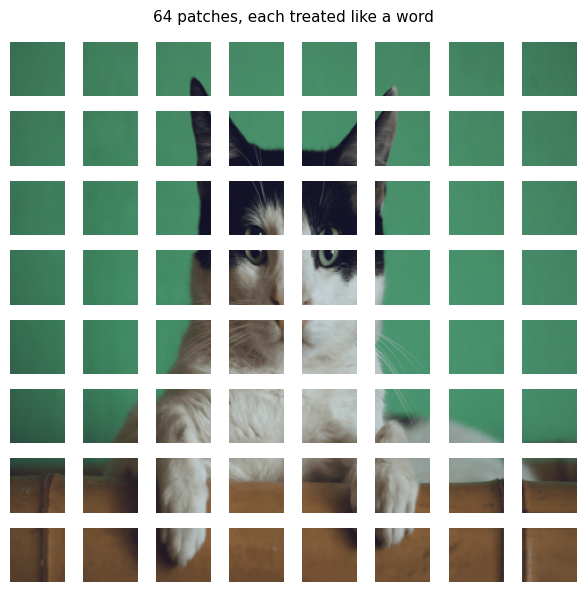

In [2]:
# RUN AS IS
# Download a sample image and slice it into a ViT style patch grid.
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/cat.png"
urllib.request.urlretrieve(url, "sample_cat.png")
img = Image.open("sample_cat.png").convert("RGB").resize((384, 384))

def show_patches(image, patch_size=48):
    """Slice an image into square patches and display them as a spaced grid,
    the way a Vision Transformer sees its input."""
    w, h = image.size
    cols, rows = w // patch_size, h // patch_size
    fig, axes = plt.subplots(rows, cols, figsize=(6, 6))
    for r in range(rows):
        for c in range(cols):
            patch = image.crop((c * patch_size, r * patch_size,
                                (c + 1) * patch_size, (r + 1) * patch_size))
            axes[r, c].imshow(patch)
            axes[r, c].axis("off")
    fig.suptitle(f"{rows * cols} patches, each treated like a word", fontsize=11)
    plt.tight_layout()
    plt.show()

show_patches(img)

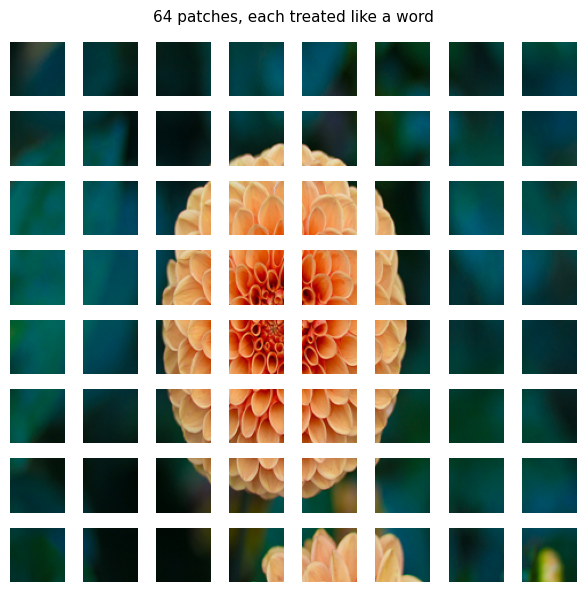

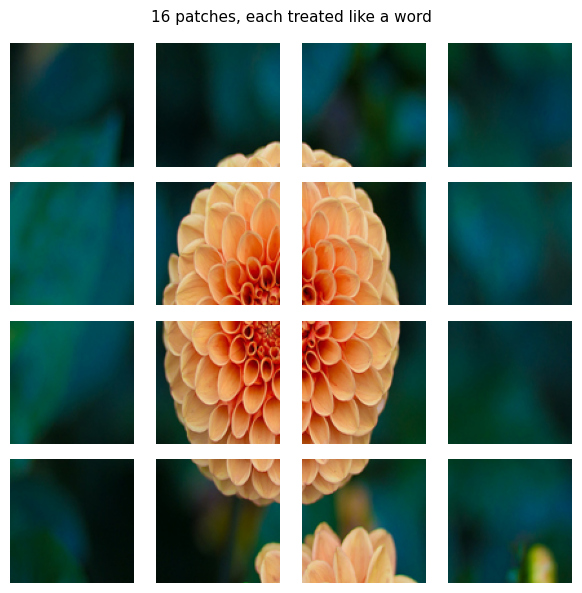

In [3]:
# YOUR CODE HERE (Patch grid, graded, 10 pts)

# TODO: load a DIFFERENT image (upload your own with the Colab folder icon,
#       or reuse a different URL) and display its patch grid at TWO patch
#       sizes: 48 and 96.
# Tip: resize to (384, 384) first so the grid divides evenly.
# Tip: img2 = Image.open("/content/yourfile.jpg").convert("RGB").resize((384, 384))
#      then call show_patches(img2, patch_size=48) and again with 96.

# TODO: your code here

# Load a different image (dog)

# Load a different image
from PIL import Image
from sklearn.datasets import load_sample_image

img2 = Image.fromarray(load_sample_image("flower.jpg"))
img2 = img2.convert("RGB").resize((384, 384))

# Display patches
show_patches(img2, patch_size=48)
show_patches(img2, patch_size=96)


### YOUR ANSWER (Patches)

*Double click and replace: With 48 pixel patches versus 96 pixel patches, which grid would give the model a more detailed "sentence" to read, and what is the tradeoff? Answer in two or three sentences using the words of an image analogy.


answer:the 48 pixel which has 64 patches give the model more detailed picture but processing takes more time and computing power. more patches means more attention work so its slower. . the 96 pixel patches have 16 big pieces so its faster to process but may missed tiny details.

## Section 3: Load the VLM and Have Your First Conversation

**RUN AS IS.** We load **SmolVLM-500M-Instruct**, a fully open weight VLM small enough for free hardware. Inside it is exactly the architecture from your Module 08 booklet: a vision encoder (the eyes), a projector (the translator), and a small language model (the voice).

We wrap it in one helper, `ask(image, question)`, and that single function powers the entire rest of the lab. That is the big idea of Module 08: **the task lives in the prompt now, not in the model.**

In [4]:
# RUN AS IS
from transformers import AutoProcessor, AutoModelForImageTextToText

MODEL_ID = "HuggingFaceTB/SmolVLM-500M-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=DTYPE).to(DEVICE)
def ask(image, question, max_new_tokens=150):
    """Ask the VLM one question about one image and return its answer."""
    messages = [{"role": "user",
                 "content": [{"type": "image"},
                             {"type": "text", "text": question}]}]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[image], return_tensors="pt").to(DEVICE)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens)
    answer = processor.batch_decode(out, skip_special_tokens=True)[0]
    # The decoded text contains the whole conversation; keep only the reply.
    return answer.split("Assistant:")[-1].strip()

print("VLM loaded. Say hello:")
print(ask(img, "Describe this image in one sentence."))

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/516 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.34k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.3k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

... (6 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

VLM loaded. Say hello:
A cat is resting its head on a wooden surface and looking at the camera.


In [5]:
from transformers import AutoProcessor, AutoModelForImageTextToText
import torch

MODEL_ID = "HuggingFaceTB/SmolVLM-500M-Instruct"

# Initialize processor and model correctly
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=DTYPE).to(DEVICE)

def ask(image, question, max_new_tokens=150):
    """Ask the VLM one question about one image and return its answer."""
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question}
        ]
    }]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[image], return_tensors="pt").to(DEVICE)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens)
    answer = processor.batch_decode(out, skip_special_tokens=True)[0]
    return answer.split("Assistant:")[-1].strip()

print("VLM successfully loaded! Testing output:")
print(ask(img, "Describe this image in one sentence."))

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

VLM successfully loaded! Testing output:
A cat is resting its head on a wooden surface and looking at the camera.


### YOUR TURN 1: Interview an Image (Graded, 10 pts)

Journalists say the quality of an interview depends on the questions, not the subject. Same here. Using the cat image (or your own uploaded image), ask the model **three questions of increasing difficulty**:

1. An easy factual question (what is in the image)
2. A detail question (color, position, count, background)
3. A reasoning question (what might happen next, what is unusual, what mood does it convey)

Print each question with its answer so both are visible in your output.

In [6]:
# YOUR CODE HERE (Your Turn 1)

question_1 = "What animal is in the image?"
question_2 = "What color is the cat, and where is it sitting?"
question_3 = "What mood does the cat seem to be in, and why?"

# TODO: write your three questions and ask them.
# Tip: a loop keeps this readable:
# for q in [question_1, question_2, question_3]:
#     print("Q:", q)
#     print("A:", ask(img, q))
#     print()



# TODO: your loop here
for q in [question_1, question_2, question_3]:
    print("Q:", q)
    print("A:", ask(img, q))
    print()

Q: What animal is in the image?
A: There is a cat in the image.

Q: What color is the cat, and where is it sitting?
A: The cat is white and black in color, and it is sitting on a wooden surface.

Q: What mood does the cat seem to be in, and why?
A: The cat seems to be in a calm mood, as it is not showing any signs of aggression or fear.



### YOUR ANSWER (Your Turn 1)

*Double click and replace: Which of your three questions got the weakest answer, and why do you think that level of question is harder for the model? Two or three sentences.*

answer: i think reasoning questions are the  hardest the model predict that the cat is in calm mood but actually cat may lookk calm but we do not know its actual feeling from yhe image.

## Section 4: One Model, Many Jobs (Graded, 10 pts)

Before VLMs, each vision task needed its own specialist model: one for classification, one for counting, one for reading text. A VLM replaces the whole shelf, because **the prompt selects the job**. Watch the demo, then make the model switch jobs yourself.

**Prompting tip that professionals rely on:** constrain the output format. "Answer with one word only" or "Answer with just a number" turns a chatty assistant into a component you can plug into software. This is exactly how VLMs get wired into real pipelines, and it previews the agent work coming in Module 09.

In [7]:
# RUN AS IS
# Job 1, classification: the prompt turns the VLM into a classifier.
print("Classifier:", ask(img, "Is this a cat, a dog, or a bird? Answer with one word only."))

Classifier: Cat.


In [8]:
# YOUR CODE HERE (Job switching)

# TODO: make the SAME model do two more jobs on the same image:
#   Job 2, counter: ask how many of something there are, demanding just a number.
#   Job 3, reader/describer: ask it to list every object it can see, one per line.
# Tip: the only thing you are allowed to change is the question string.
#      That is the whole point of this section.

# TODO: Job 2 here
print("Job 2 - Counting")
print("A:", ask(img, "How many cats are in the image? Answer with just a number."))


# TODO: Job 3 here
print("Job 3 - Describing")
print("A:", ask(img, "List every object you can see in the image, one per line."))



Job 2 - Counting
A: 1.
Job 3 - Describing
A: Green background. Cat.


### YOUR ANSWER (One model, many jobs)

*Double click and replace: In Module 06 you used a dedicated detector (YOLO) for finding objects. Name one advantage the specialist detector still has over the VLM you just prompted, and one advantage the VLM has over the specialist. Two or three sentences.*

answer: yolo is usefull when you want to  detec and locate the object  so its also locate the object that is its advantage.smolVLM can answer open ended different questions  about the images using NLP while standard yolo can not do this.

## Section 5: Workforce Task A, Accessibility Alt Text (Graded, 10 pts)

Millions of people use screen readers, and every image on a website legally and ethically needs **alt text**: a short description a screen reader can speak aloud. Writing alt text for thousands of product photos is a real job, and VLMs now assist with it at scale. But quality depends entirely on the prompt.

Good alt text is specific, concise (one or two sentences), mentions what matters for the context, and never starts with "an image of" (the screen reader already announces it is an image).

Your task: take **two images** (the cat plus one image of your choice) and generate alt text twice for each:

1. First with a **weak prompt**: just "Describe this image."
2. Then with a **professional prompt you write** that encodes the rules above.

In [9]:
# YOUR CODE HERE (Workforce task A)

# TODO: write your professional alt text prompt. Encode the rules:
#       concise, specific, useful for a shopper or reader, never "an image of".
# Tip: you can put instructions AND constraints in one question, for example:
#      "Write alt text for this image for a screen reader user. One sentence,
#       specific, do not begin with the words an image of."

weak_prompt = "Describe this image."
pro_prompt = "Write clear and specific alt text for a screen reader user in one or two short sentences. Mention important visible details useful for a shopper or reader. Do not start with 'an image of'."


# TODO: run both prompts on BOTH images and print all four results, clearly
#       labeled so the improvement is easy to see.
# Image 1: Cat
print("Cat - Weak Prompt:")
print(ask(img, weak_prompt))

print("\nCat - Professional Prompt:")
print(ask(img, pro_prompt))

# Image 2: Flower
print("\nFlower - Weak Prompt:")
print(ask(img2, weak_prompt))

print("\nFlower - Professional Prompt:")
print(ask(img2, pro_prompt))

Cat - Weak Prompt:
The image depicts a domestic cat resting on a wooden surface, likely a table or shelf. The cat has a predominantly white body with patches of black on its head, back, and legs. The fur on its face is a mix of white and black, with the white areas including the eyes, nose, and ears. The cat's eyes are a light green color, and its pupils are dilated, indicating that it is either awake or very relaxed.

The cat's paws are white, with the left paw resting on the edge of the wooden surface, while the right paw is slightly raised, with the claws extended. The cat's tail is not visible in the image. The background is a solid green color, which provides a stark contrast to

Cat - Professional Prompt:
A cat is lying on a wooden surface.

Flower - Weak Prompt:
The image depicts two orange-colored flowers, which appear to be chrysanthemums, in a close-up view. The flowers are fully bloomed, with their petals spread open in a fan-like shape. The petals are a light orange color, 

### YOUR ANSWER (Alt text)

*Double click and replace: Compare the weak and professional outputs. What specifically improved, and what would you still fix by hand before publishing? Two or three sentences.*


answer: weak prompt gives us more detailed answer and professional prompt gives rule base specific answer but i noticed that while creating a shorter rule based answer professional prompt missed  important detail like color of cat and the color of the flower.

## Section 6: Workforce Task B, Reading Documents and Charts (Graded, 10 pts)

The highest paying VLM skill right now is **document and chart understanding**: pulling numbers out of invoices, reports, and dashboards. Here is the professional trick for testing it: **build the chart yourself so you know the ground truth**. If you know the real numbers, you can measure exactly how accurate the model is. Never trust an extraction you cannot check.

**RUN AS IS** builds a sales chart with known values. Then you interrogate it.

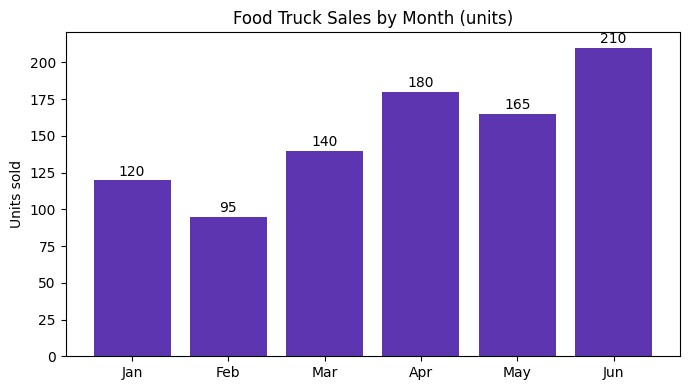

Chart built. Ground truth: {'Jan': 120, 'Feb': 95, 'Mar': 140, 'Apr': 180, 'May': 165, 'Jun': 210}


In [10]:
# RUN AS IS
# Build a bar chart with KNOWN values, save it, and load it as an image.
import matplotlib.pyplot as plt
from PIL import Image

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [120, 95, 140, 180, 165, 210]   # ground truth, we KNOW these numbers

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(months, sales, color="#5E35B1")
ax.set_title("Food Truck Sales by Month (units)")
ax.set_ylabel("Units sold")
for i, v in enumerate(sales):
    ax.text(i, v + 3, str(v), ha="center", fontsize=10)
plt.tight_layout()
plt.savefig("sales_chart.png", dpi=110)
plt.show()

chart = Image.open("sales_chart.png").convert("RGB")
print("Chart built. Ground truth:", dict(zip(months, sales)))

### Chart reading with ground truth check
Each question is paired with its true answer from the `sales` data, so the code marks each model answer correct or wrong.

In [11]:
# YOUR CODE HERE (Workforce task B)
# TODO: ask the model AT LEAST three questions about the chart and print the
#       answers next to the true values so accuracy is visible. Ideas:
#   1. Which month had the highest sales?
#   2. How many units were sold in March? (Answer with just the number.)
#   3. Did sales go up or down between April and May?
# Tip: ask(chart, your_question)
# Tip: at least one question should require comparing two bars, which is
#      harder than reading one printed number.
# Each item: (question, true answer from the sales data)
questions = [
    ("Which month had the highest sales?", "Jun"),
    ("How many units were sold in March? Answer with just the number.", "140"),
    ("Did sales go up or down between April and May?", "down"),   # 180 -> 165
]

score = 0
for i, (q, truth) in enumerate(questions, 1):
    answer = ask(chart, q)
    correct = truth.lower() in answer.lower()   # simple match check
    score += correct
    print(f"Q{i}: {q}")
    print(f"   Model: {answer}")
    print(f"   Truth: {truth}  ->  {'CORRECT' if correct else 'WRONG'}")
    print()

print(f"Score: {score}/{len(questions)}")

Q1: Which month had the highest sales?
   Model: Jun
   Truth: Jun  ->  CORRECT

Q2: How many units were sold in March? Answer with just the number.
   Model: 140.
   Truth: 140  ->  CORRECT

Q3: Did sales go up or down between April and May?
   Model: Sales went up.
   Truth: down  ->  WRONG

Score: 2/3


### YOUR ANSWER (Chart reading)

*Double click and replace: Score the model: how many of your questions did it answer correctly against the ground truth? Would you trust it unsupervised with a company's financial dashboard? Two or three sentences.*


answer: smolVLM gave two answers correct out of three answers. i will not left it unsupervised as it is a company financial dashboard. even  tiny mistake in reading numbers could lead to a incorrect business decision.

## Section 7: YOUR TURN 2, The Hallucination Hunt (Graded, 10 pts)

Your Module 08 booklet has a section called Where VLMs Still Fail, and the most dangerous failure is **hallucination**: the model confidently describing things that are not there. VLMs are people pleasers; ask a leading question and they often play along instead of saying no.

Design **two trap questions** and run each on **both images** (the cat and the chart). A trap question presupposes something false, for example:

* "What color is the dog's collar?" (asked about an image with no dog)
* "What does the sign in the background say?" (no sign exists)
* "Why did sales drop in June?" (they rose)

A model passes the trap by correcting you. It fails by inventing an answer.

In [13]:
# YOUR CODE HERE (Your Turn 2)

# TODO: write two trap questions of your own (do not copy the examples) and
#       run each on BOTH images, printing all four exchanges clearly.
# Tip: the best traps sound casual and confident, exactly like a distracted
#      coworker would ask.

trap_1 = "What color is the red car parked next to the main subject?"
trap_2 = "What does the date printed in the top-right corner say?"


# TODO: run both traps on img and on chart, print all four Q and A pairs
for image_name, image in [("Cat", img), ("Sales Chart", chart)]:
    for question in [trap_1, trap_2]:
        print("Image:", image_name)
        print("Q:", question)
        print("A:", ask(image, question))
        print()

Image: Cat
Q: What color is the red car parked next to the main subject?
A: There is no car present in the image; it only features a cat.

Image: Cat
Q: What does the date printed in the top-right corner say?
A: There is no date printed in the top-right corner of the image.

Image: Sales Chart
Q: What color is the red car parked next to the main subject?
A: Blue.

Image: Sales Chart
Q: What does the date printed in the top-right corner say?
A: Food Truck Sales by Month (units).



### YOUR ANSWER (Hallucination report)

*Double click and replace: For each trap, did the model correct you or play along? Why is this failure mode more dangerous in a workplace than simply getting a count wrong? Three or four sentences.*

answer:for the cat image , model gave correct answers for both the trap questions that their is no blue car and date . however in the chart image case model hallucinated and replied both question wrong that their is blue car and turn chart tiltle as date so in the chart case model gave both answers wrong . at workplace it is more dangerous then a simple counting error because employess can trust it blindly and can take wrong decisions.

## Section 8: Preview, The Agent's Eyes (Bridge to Module 09)

**RUN AS IS.** In Module 09 you will build AI agents that perceive, reason, and act. Their perception step is exactly what you have been doing all lab: a VLM answering questions about what it sees. Here is a thirty second preview: we ask the model not just to describe, but to **recommend an action**, which is the seed of the agent loop.

In [14]:
# RUN AS IS
# The same ask() function, but the prompt now requests a decision.
agent_question = (
    "You are a monitoring assistant for a pet daycare. Based on this camera "
    "image, report the situation in one sentence and recommend one action. "
    "Format: SITUATION: ... ACTION: ..."
)
print(ask(img, agent_question))

Monitor the cat's eye color.


Notice what changed: nothing in the model, everything in the prompt. Perception plus a decision format is the doorway to agents. Hold that thought for two weeks.

## Section 9: Try It Yourself, The Deployment Audit (Graded, 20 pts)

This section is fully yours. No scaffolding, no starter code. Your only tools: `ask()`, `show_patches()`, matplotlib, and your judgment.

**The scenario:** You are a junior CV technician. Your manager is considering using a small VLM for one workplace task and asks you to **audit it before anyone trusts it**. You choose the scenario:

* Retail: describing product photos for a store website
* Safety: reporting what is visible on a workplace camera image
* Accessibility: alt text for a community organization's photo library
* Education: describing diagrams or charts for students
* Your own idea (name it clearly)

**Your deliverable, in cells you write yourself:**

1. **The scenario and test set (5 pts):** name your scenario and assemble two or three test images that fit it (upload your own, reuse the chart trick from Section 6 to build controlled test images, or reuse the provided images if they genuinely fit).
2. **The reliability test (5 pts):** design ONE prompt for the task, then test it for consistency by asking the same thing **three different ways** (rephrase it twice) on the same image. A dependable tool gives consistent answers; a fragile one changes its story.
3. **The audit memo (10 pts):** in the answer cell below, write a five to eight sentence memo to your manager: what you tested, what the model got right, what it got wrong or inconsistent, one hallucination risk specific to your scenario, and your verdict: deploy with human review, deploy unsupervised, or do not deploy. Take a position and defend it with your evidence.

**GPU saver:** ten to fifteen questions total is plenty. A sharp audit beats a big one.

In [15]:
# YOUR CODE HERE (Try It Yourself)
# Test 1: Check image details
print("Q: What color is the cat?")
print("A:", ask(img, "What color is the cat?"))

# Test 2: Check for hallucination
print("\nQ: How many dogs are beside the cat?")
print("A:", ask(img, "How many dogs are beside the cat?"))

# Build your audit below. Add as many cells as you need.
# Your toolbox:
#   ask(image, question)
#   show_patches(image, patch_size=...)
#   matplotlib and PIL for building controlled test images
# Reminder: print every question next to its answer so your memo's evidence
# is visible in the notebook output.

Q: What color is the cat?
A: The cat is white and black in color.

Q: How many dogs are beside the cat?
A: There are two dogs beside the cat.


### Audit scenario and test set
Scenario: Education. Describing charts for students.
Test images: two bar charts I built with known values, so I know the true answers.

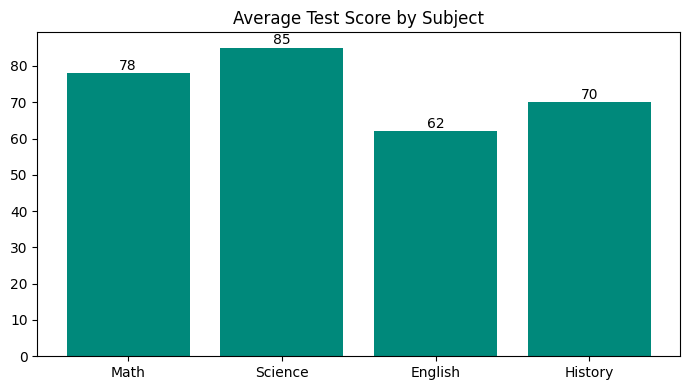

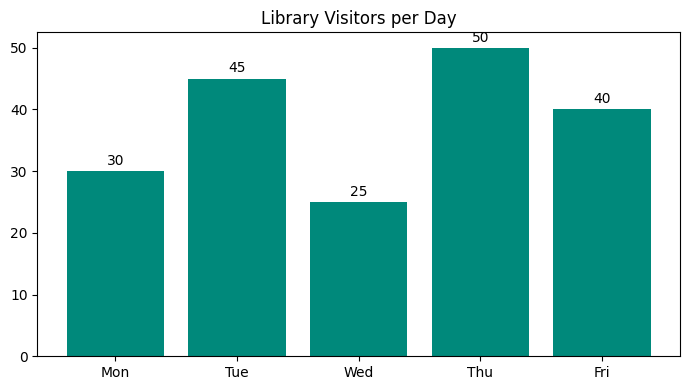

Truth A: highest = Science (85), lowest = English (62)
Truth B: highest = Thu (50), lowest = Wed (25)


In [17]:
import matplotlib.pyplot as plt
from PIL import Image

def make_chart(labels, values, title, filename):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(labels, values, color="#00897B")
    ax.set_title(title)
    for i, v in enumerate(values):
        ax.text(i, v + 1, str(v), ha="center")
    plt.tight_layout(); plt.savefig(filename, dpi=110); plt.show()
    return Image.open(filename).convert("RGB")

chart_a = make_chart(["Math", "Science", "English", "History"], [78, 85, 62, 70],
                     "Average Test Score by Subject", "chart_a.png")
chart_b = make_chart(["Mon", "Tue", "Wed", "Thu", "Fri"], [30, 45, 25, 50, 40],
                     "Library Visitors per Day", "chart_b.png")
print("Truth A: highest = Science (85), lowest = English (62)")
print("Truth B: highest = Thu (50), lowest = Wed (25)")

### Reliability test
One task asked three different ways on chart A. A reliable tool should give the same answer every time.

In [22]:
phrasings = [
    "which subject has the lowest average score?",
    "tell me ,which subject has the lowest average score?",
    "answer with one word  which subject has the lowest average score?",



]

for name, image in [("Chart A", chart_a), ]:
    print(f"===== {name} =====")
    for i, p in enumerate(phrasings, 1):
        print(f"Phrasing {i}: {p}")
        print("A:", ask(image, p))
        print()

===== Chart A =====
Phrasing 1: which subject has the lowest average score?
A: English.

Phrasing 2: tell me ,which subject has the lowest average score?
A: English.

Phrasing 3: answer with one word  which subject has the lowest average score?
A: English.



### YOUR ANSWER (Audit memo)

*Double click and replace: your five to eight sentence memo to your manager. What you tested, what worked, what failed or wavered, one scenario specific hallucination risk, and your verdict with reasons.*

answer:I selected the education scenario in which two bar charts built named average test score by subject and library visitors per day. I checked the highest and lowest bar results of both charts then ask 3 asked same questions in 3 different ways to model about chart A that "which subject has the lowest averge score and all 3 times it reply with "ENGLISH " which was the right answer.although all answers are correct but as its an educational data so human in the loop is required so if model hullicinate, it can be catched.

## Section 10: Reflection Questions (Graded, 20 pts, 2 each)

Answer each question in complete sentences directly in its YOUR ANSWER cell. Short bullet answers will not earn full credit. I want your reasoning in your own words.

**Q1. Patches as words.** Explain to a friend with no AI background how a Vision Transformer reads an image, using the patch grid you made in Section 2. Use your own analogy, not one from this notebook.

### YOUR ANSWER


i would describe vision transformer as reading a news papper or preparing a presentation , divide it in to small parts or portions then understand each part saperately similarly it divides images in to patches and understan them seperately instead process it at once. in section 2 we used 48 pixel patches, which created 64 small pieces, and 96 pixel patches which create 16 large pieces. small patches capture more detail while large patches decreases the ampont of processing.

**Q2. The three part architecture.** A VLM has eyes (vision encoder), a translator (projector), and a voice (language model). When your model hallucinated in Section 7, which part do you suspect was most responsible, and why?

### YOUR ANSWER

*i think two factors are responsible for possibly first language model and second vision encoder . in section 7 when we asked the color of the car it generated the answer even the information was not present in the image . the vision incoder also struggleed to find what was actually present in the image.

**Q3. The prompt is the task.** In Section 4 one model did several jobs. What does this mean for how CV teams will be organized in the workplace: fewer specialist models to maintain, or new problems to manage? Name one of each.

### YOUR ANSWER
In Section 4, I realize that one VLM can do different tasks simply by changing the prompt. This could help companies reduce the number of specialized models they required to maintain, saving time and resources. However, teams still have to check results for hullicination because some time models predict totally wrong results.t



**Q4. Constrained outputs.** Why does "answer with just a number" matter so much when a VLM is wired into software instead of chatting with a person? Give a concrete example of what breaks without it.

### YOUR ANSWER

Asking the model to give answer in a number is important because software often required information in a certain format. For example, if an inventory system asks how many products are in hand, it may expect the number 10 instead of long sentence. If the model returns extra words, the software might not  process the answer correctly.



**Q5. Small versus frontier.** You used a 500 million parameter open model today; Module 08 covered frontier models thousands of times larger. Name two workplace situations where the small local model is the RIGHT choice even though it is weaker.

### YOUR ANSWER

A small model could be a  better choice when a company needs to protect private information, such as internal documents or customer records, because the data can stay on its own systems. It can also be helpful for simple tasks in places with limited internet access or a small budget. smaller models can be cheaper and easier to run.

**Q6. Alt text ethics.** Who is harmed when auto generated alt text is wrong, and why is "a human reviews every caption" easier to promise than to deliver at the scale of a real website?

### YOUR ANSWER

 it effects mainly those people who depends on screen readers to understand.If important details are missing or incorrect, they may misinterpret a product or the information on a website. Although human reviews is the better option instead scroll and check many images which takes time  and money .

**Q7. Ground truth.** In Section 6 you built the chart yourself so you knew the true numbers. Why is this a professional habit, and what goes wrong when teams evaluate AI tools on data where nobody knows the right answers?

### YOUR ANSWER

knowing the ground truth is important so it allow to check the model output with the coorect answers. in the section 6 we created the chart and we know the ground truth so when mnodel predict the wrong predictions we easily know th the answer are incorrect. if a company test AI without knowing the ground truth so it is difficut to catch model hallucination.

**Q8. Hallucination versus error.** Using your Section 7 results, explain the difference between a model being wrong and a model hallucinating. Why is the second one harder to catch in a busy workplace?

### YOUR ANSWER

a normall error occur when a model gives an incorrect answer for example reading a number incorrectly.  hallucination is when it invents answers from its own confidently.in section 7,smolVLM predict that their is a blue car in the image even their was no car in the image.because model is sound confident that is why it is difficult to catch hallucination at busy work place.

**Q9. The audit mindset.** Your Try It Yourself verdict required taking a position. What evidence would have changed your verdict to the opposite one? Being able to answer this is what separates an audit from an opinion.

### YOUR ANSWER

I suggest human supervision because SmolVLM hallucinated objects that were not their in our test images. My decision would have been different if the model had continously identified the correct objects and rejected misleading questions across many new images. I also want to see right results on real workplace tasks before recommending independent use.  an audit should be based on test results rather than personal opinions.

**Q10. Changed mind.** Before this lab, what did you believe about how AI understands images that turned out to be wrong or incomplete? Be specific about which section changed your mind.

### YOUR ANSWER

I thought that a pre-trained model would usually recognize what was their in an image and do not describing things that were not there. Section 7 changed my understanding because SmolVLM correctly rejected false questions about the cat but invented a blue car in the sales chart. I learned that even a pretrained model can hallucinate, and its answers need to be checked instead of trusted automatically.



## Section 11: Optional Bonus Challenges (up to +20)

Each completed challenge earns 5 bonus points. Pick any, all, or none. All four are light on compute.

**Bonus A, The tiny sibling (+5):** Load `HuggingFaceTB/SmolVLM-256M-Instruct` (half the size, a fast extra download) and rerun your three Your Turn 1 questions on it. In one or two sentences: what did shrinking the model cost?

**Bonus B, The receipt reader (+5):** Using PIL, draw your own fake receipt image (store name, three items with prices, a total) with `ImageDraw.text`, then ask the model to extract the total and one item price. You know the ground truth because you drew it.

**Bonus C, The patch size probe (+5):** Take one image with small important detail (text or a small object). Show its patch grid at 96 pixels, then ask the model a question about that small detail. Connect what you see in the grid to how the model answered, in one or two sentences.

**Bonus D, Your own photo set (+5):** Complete your Try It Yourself audit entirely with photos you took yourself. If you already did, say so here and point to the cells.

In [16]:
# YOUR CODE HERE (Optional bonus work)
# Label each attempt clearly with a comment: # BONUS A, # BONUS B, etc.
# Memory tip for Bonus A: load the 256M model AFTER you finish everything
# else, and if memory complains, run:
#   del model; import gc; gc.collect(); torch.cuda.empty_cache()
# before loading the smaller one.

## Section 12: Submission Checklist

1. Choose Runtime, then Run all, one final time. Confirm there are no errors and every question and answer pair is visible.
2. Check that every **YOUR ANSWER** cell has your words in it (search the notebook for the word "replace" to find any you missed).
3. File, Download, Download .ipynb, **with all outputs visible**. Do not clear outputs.
4. Name it **L08_LastName_FirstName_ITAI1378.ipynb** and submit the notebook to Canvas. The notebook is the only deliverable.

Today you interviewed images, made one model wear five hats, caught it lying, and wrote a professional audit, all on a model small enough to run on a laptop. In Module 09 the VLM you just tamed becomes the **eyes of an agent** that perceives, reasons, and acts. You already wrote its first perception prompt in Section 8.

*Email or message me if you have any questions.*